# Week 43, Tuesday session: the measures of a classifier, and one case — your own confusion matrix, ROC curve and AUC

**FYS-STK3155/4155, Tuesday October 20, 2026**

Today has two parts. **First** (about 25 minutes, in plenum) we go through
Monday's worked screening example measure by measure — what each number is,
what it asks, and what it cannot say — together with the three facts behind
them: accuracy as a prevalence-weighted average, $F_1$ as a harmonic mean,
and the AUC as a probability about pairs. **Then** (the rest of the double
session, in groups) **one case**, worked in this notebook: a binary
classifier of the kind Project 2 asks for — logistic regression and a
one-hidden-layer network, your own code — on a small, fast data set, with
the confusion matrix, the ROC curve and the AUC computed by hand and checked
against `scikit-learn`, and finally the `scikit-learn` calls you will use in
Project 2.

The data are the $8\times8$ digits shipped with `scikit-learn` (1797 images,
seconds per run), so that you can rerun every step as often as you like. The
question is *"is this digit an eight?"* — about one image in ten is, so the
problem is imbalanced in the way one-against-the-rest readings of the
ten-class matrix in Project 2 always are. The weekly exercises
(`exercisesweek43.ipynb`, deadline **Friday October 23**) are the same two
steps — the functions, then MNIST — and Project 2 does them on the full
MNIST set.

There is no validation set today and no cross-validation: how to do that
for your Project 2 network is the topic of next week's Tuesday session and
exercises. Seed 2026 throughout, so that your numbers are ours.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn import metrics as skm

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"
GREEN = "#228833"
np.set_printoptions(precision=4, suppress=True)
np.random.seed(2026)

## Part A: the worked example, measure by measure

A test for a condition with prevalence $\pi=2\%$ is applied to 1000 people:

$$
\begin{array}{c|cc}
 & \text{predicted } 1 & \text{predicted } 0\\ \hline
\text{true } 1 & \mathrm{TP}=15 & \mathrm{FN}=5\\
\text{true } 0 & \mathrm{FP}=40 & \mathrm{TN}=940
\end{array}
$$

Twenty people have the condition; the test finds fifteen and raises forty
false alarms. Next to it we keep the "test" that declares everybody healthy
($0, 20, 0, 980$). Rows are the truth, columns the decision; **FN** are the
*missed* cases (the dangerous error in screening), **FP** the *false alarms*
(a follow-up, not a life). Every measure below is a function of these four
counts.

| measure | definition | our test | everybody healthy | what it asks |
|---|---|---|---|---|
| accuracy | $(\mathrm{TP}+\mathrm{TN})/n$ | $0.955$ | $\mathbf{0.980}$ | decisions right, all alike |
| precision | $\mathrm{TP}/(\mathrm{TP}+\mathrm{FP})$ | $0.273$ | $0$ ($0/0$) | of those flagged, how many were? |
| recall (TPR) | $\mathrm{TP}/(\mathrm{TP}+\mathrm{FN})$ | $0.750$ | $0$ | of the sick, how many found? |
| specificity (TNR) | $\mathrm{TN}/(\mathrm{TN}+\mathrm{FP})$ | $0.959$ | $1.000$ | of the healthy, how many left alone? |
| $F_1$ | $2\,\mathrm{prec}\cdot\mathrm{rec}/(\mathrm{prec}+\mathrm{rec})$ | $0.400$ | $0$ | both of the two above |
| balanced accuracy | $\tfrac12(\mathrm{TPR}+\mathrm{TNR})$ | $0.855$ | $0.500$ | accuracy at equal class weights |
| MCC | $(\mathrm{TP}\,\mathrm{TN}-\mathrm{FP}\,\mathrm{FN})/\sqrt{D}$ | $0.436$ | $0$ | correlation of $y$ and $\tilde y$ |

with $D=(\mathrm{TP}+\mathrm{FP})(\mathrm{TP}+\mathrm{FN})(\mathrm{TN}+\mathrm{FP})(\mathrm{TN}+\mathrm{FN})$.

**Accuracy prefers the useless test.** With $n_+=\mathrm{TP}+\mathrm{FN}$,
$n_-=\mathrm{FP}+\mathrm{TN}$ and $\pi=n_+/n$,
$$\mathrm{accuracy}=\frac{n_+}{n}\frac{\mathrm{TP}}{n_+}+\frac{n_-}{n}\frac{\mathrm{TN}}{n_-}=\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}
=0.02\times0.75+0.98\times0.959=0.955,$$
so whatever the test does on the sick enters with weight $0.02$. Always
compare an accuracy with the majority-class accuracy $\max(\pi,1-\pi)$ and
quote the fraction of the *remaining* error removed,
$1-(1-\mathrm{acc})/(1-p_0)$ — here negative. Balanced accuracy is the same
average with equal weights: the accuracy on a balanced population, $0.5$ for
a coin.

**Recall is about the misses, precision about the false alarms.** The
denominators differ: the truth ($n_+$) for recall, our decision
($\mathrm{TP}+\mathrm{FP}$) for precision. The test finds three quarters of
the sick, but three of four people called back are healthy — because the
condition is rare: 40 false alarms out of 980 healthy people is only a 4%
false positive rate. Lowering the threshold raises recall and lowers
precision; which matters is a question about the application (screening:
recall; spam filter: precision).

**$F_1$ is small whenever either is small.** With $m=\min(\mathrm{prec},\mathrm{rec})$
and $M=\max$, $F_1=2m/(1+m/M)$, so $m\le F_1\le2m$. That is why the
harmonic mean: for precision 1 and recall 0.1 the arithmetic mean says
$0.55$, the harmonic mean $0.18$ — perfect on one axis and useless on the
other is useless. $F_1$ never looks at TN.

**MCC is the correlation between labels and decisions** (Section 2.4): it
uses all four counts, is symmetric in the two classes, and is $0$ for the
empty rule — the one scalar that is hard to fool by imbalance.

**The AUC is a probability about pairs.** Every threshold gives one
confusion matrix, hence one point $(\mathrm{FPR},\mathrm{TPR})$; sweeping
the threshold traces the ROC curve. Sort all $n=n_++n_-$ scores increasingly
and let $R_i$ be the rank of the $k_i$th positive: below it sit $R_i-1$
samples, $k_i-1$ of them positives, so it outranks $R_i-k_i$ negatives.
Summed over the positives, $\sum_iR_i-\tfrac12n_+(n_++1)$ correctly ordered
pairs out of $n_+n_-$:
$$\mathrm{AUC}=\frac{\sum_{i\in\mathrm{pos}}R_i-\tfrac12n_+(n_++1)}{n_+n_-}
=\mathrm{Prob}(\text{a random positive outscores a random negative}),$$
the Mann–Whitney statistic (ties: average rank, half a pair), equal to the
trapezoidal area under the curve. A random ranking, or all scores equal
(every $R_i=(n+1)/2$), gives $0.5$. It depends only on the ranking: not on
the threshold, and not on the prevalence — duplicate every positive and TP
and FN double together, so every TPR is unchanged and FPR never saw the
positives. Precision has FP in its denominator, so the precision–recall
curve *does* move; its floor is $\pi$.

**Why we train on the cross entropy and report the rest.** Accuracy,
precision, recall, $F_1$ and the AUC are functions of the decisions or of
the ranking: staircases in the parameters, zero gradient wherever it exists.
The cross entropy is the smooth surrogate, minimised *roughly* where the
decisions are right — not exactly: with one positive and one negative, model
A ($p=0.51$, $0.49$) has accuracy 1 and cross entropy $0.673$; model B
($0.99$, $0.60$) has accuracy $0.5$ and cross entropy $0.463$.

The cell below reproduces every number of the table from the four counts
and checks them against `scikit-learn`.

In [2]:
def confusion_matrix(y_true, y_pred):
    """Eq. (5.67): the four counts TP, FN, FP, TN for labels in {0, 1}; the positive class is 1."""
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn


def classification_report(y_true, y_pred):
    """Every scalar summary is a function of the four counts: Eqs. (5.68)-(5.70) and a few more."""
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp else 0.0          # of those flagged positive, how many were?
    recall = tp / (tp + fn) if tp + fn else 0.0             # of the positives, how many did we find? (= TPR)
    specificity = tn / (tn + fp) if tn + fp else 0.0        # of the negatives, how many did we leave alone? (= 1 - FPR)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0  # Matthews correlation coefficient: correlation of y and y_hat
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=accuracy, precision=precision, recall=recall,
                specificity=specificity, f1=f1, balanced_accuracy=balanced, mcc=mcc)


In [3]:
tp, fn, fp, tn = 15, 5, 40, 940
y_true = np.r_[np.ones(tp + fn), np.zeros(fp + tn)]
y_pred = np.r_[np.ones(tp), np.zeros(fn), np.ones(fp), np.zeros(tn)]
y_empty = np.zeros_like(y_true)                       # "everybody healthy"
for name, yp in (("our test", y_pred), ("everybody healthy", y_empty)):
    r = classification_report(y_true, yp)
    print(f"--- {name}: TP {r['TP']} FN {r['FN']} FP {r['FP']} TN {r['TN']}")
    print("  " + "  ".join(f"{k} {r[k]:.3f}" for k in ("accuracy", "precision", "recall", "specificity", "f1", "balanced_accuracy", "mcc")))
    print(f"  sklearn: accuracy {skm.accuracy_score(y_true, yp):.3f} precision {skm.precision_score(y_true, yp, zero_division=0):.3f} "
          f"recall {skm.recall_score(y_true, yp):.3f} F1 {skm.f1_score(y_true, yp):.3f} "
          f"balanced {skm.balanced_accuracy_score(y_true, yp):.3f} MCC {skm.matthews_corrcoef(y_true, yp):.3f}")
pi = (tp + fn) / (tp + fn + fp + tn)
print(f"accuracy = pi*recall + (1-pi)*specificity = {pi * 0.75 + (1 - pi) * 940 / 980:.3f}")
for name, p_pos, p_neg in (("model A", 0.51, 0.49), ("model B", 0.99, 0.60)):
    print(f"{name}: accuracy {0.5 * ((p_pos > 0.5) + (p_neg <= 0.5)):.1f}, cross entropy {-0.5 * (np.log(p_pos) + np.log(1 - p_neg)):.3f}")

--- our test: TP 15 FN 5 FP 40 TN 940
  accuracy 0.955  precision 0.273  recall 0.750  specificity 0.959  f1 0.400  balanced_accuracy 0.855  mcc 0.436
  sklearn: accuracy 0.955 precision 0.273 recall 0.750 F1 0.400 balanced 0.855 MCC 0.436
--- everybody healthy: TP 0 FN 20 FP 0 TN 980
  accuracy 0.980  precision 0.000  recall 0.000  specificity 1.000  f1 0.000  balanced_accuracy 0.500  mcc 0.000
  sklearn: accuracy 0.980 precision 0.000 recall 0.000 F1 0.000 balanced 0.500 MCC 0.000
accuracy = pi*recall + (1-pi)*specificity = 0.955
model A: accuracy 1.0, cross entropy 0.673
model B: accuracy 0.5, cross entropy 0.463


## Part B, Case 1: your own confusion matrix, ROC curve and AUC

**The five steps.** (1) The data and the number to beat. (2) Two classifiers
with your own code. (3) The confusion matrix by hand: four counts and the
measures made from them. (4) The ROC curve and the AUC, from one sorted
pass. (5) The same with `scikit-learn` — the calls you will use in
Project 2.

### The network of week 41, unchanged

Replace these cells by your own Project 2 code if you have it; the only
requirement is `predict` returning a probability for the binary head.

In [4]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


def one_hot(y, n_classes=None):
    """Integer labels -> one-hot rows."""
    n_classes = int(np.max(y)) + 1 if n_classes is None else n_classes
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y


### Step 1: the data, and the number to beat

1797 images of $8\times8$ pixels with values $0$–$16$, scaled to $[0,1]$;
$y=1$ for the eights. We split off a test set of 20% (stratified, so that it
has the same fraction of eights) and train on the rest. Before any model:
what accuracy does the classifier that never says "eight" get?

train 1437, test 360 images
fraction of eights: train 0.097, test 0.097
accuracy of 'never an eight' on the test set: 0.9028


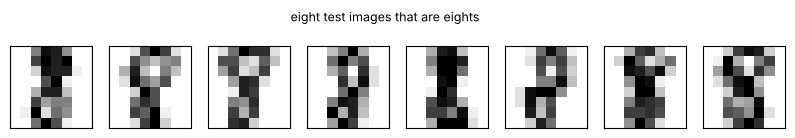

In [5]:
digits = load_digits()
X_all = digits.data / 16.0
d_all = digits.target
y_all = (d_all == 8).astype(float)

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=2026, stratify=d_all)

print(f"train {len(y_train)}, test {len(y_test)} images")
print(f"fraction of eights: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
print(f"accuracy of 'never an eight' on the test set: {1 - y_test.mean():.4f}")

fig, ax = plt.subplots(1, 8, figsize=(10, 1.6))
for a, i in zip(ax, np.where(y_test == 1)[0][:8]):
    a.imshow(X_test[i].reshape(8, 8), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
fig.suptitle("eight test images that are eights", fontsize=9)
plt.show()

### Step 2: two classifiers with your own code

Logistic regression is the week-41 network with *no* hidden layer and the
sigmoid head: `sizes = [64, 1]`. The second classifier has one hidden layer
of 32 ReLU units. Both are trained with plain SGD ($M=32$, $\gamma=0.1$,
150 epochs) on the training set; the cross entropy is what is minimised,
and the test accuracy is printed per epoch so that we can see the two
settle.

logistic regression: 65 parameters, final cost 0.0915, test accuracy 0.9639


one hidden layer of 32: 2113 parameters, final cost 0.0074, test accuracy 0.9778


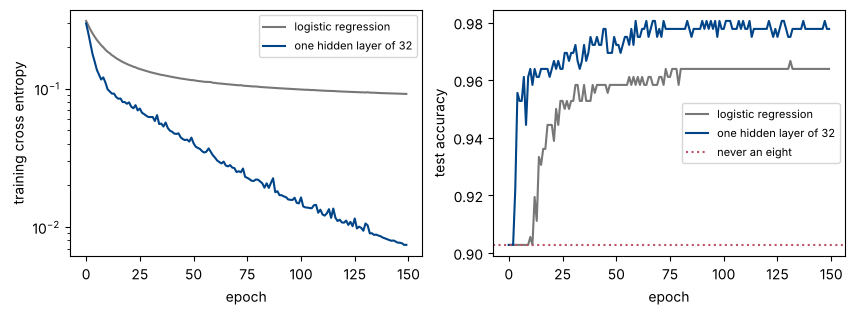

In [6]:
models = {}
for name, sizes, act in (("logistic regression", [64, 1], "sigmoid"),
                         ("one hidden layer of 32", [64, 32, 1], "relu")):
    layers = create_layers(sizes, act, np.random.default_rng(2026))
    layers, hist = train(X_train, y_train[:, None], layers, act, "binary", gamma=0.1, epochs=150,
                         batch_size=32, X_test=X_test, y_test=y_test)
    models[name] = {"layers": layers, "act": act, "history": hist,
                    "p_test": predict(X_test, layers, act, "binary")[:, 0],
                    "n_params": sum(W.size + b.size for W, b in layers)}
    print(f"{name}: {models[name]['n_params']} parameters, final cost {hist['cost'][-1]:.4f}, "
          f"test accuracy {hist['test_accuracy'][-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for name, col in zip(models, (GREY, BLUE)):
    ax[0].semilogy(models[name]["history"]["cost"], color=col, label=name)
    ax[1].plot(models[name]["history"]["test_accuracy"], color=col, label=name)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training cross entropy"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test accuracy"); ax[1].axhline(1 - y_test.mean(), color=RED, ls=":", label="never an eight")
ax[1].legend(fontsize=8)
plt.show()

**Checkpoint.** Both accuracies are above $0.95$. Is that good? Compare with
the number from step 1 before you answer — and notice that the two
classifiers look alike on accuracy. The next steps tell them apart.

### Step 3: the confusion matrix by hand, Eqs. (5.67)–(5.70)

Four counts — TP, FN, FP, TN — for the decision $p>0.5$, then the measures
of Part A. Write `confusion_matrix` and `classification_report` yourself
from the definitions before you look at ours (they are the functions of
Part A), then check against `sklearn.metrics.confusion_matrix` — and mind
its layout: rows true $0/1$, columns predicted $0/1$, so TP sits in the
lower right.

In [7]:
for name in models:
    p = models[name]["p_test"]
    r = classification_report(y_test, p > 0.5)
    print(f"--- {name}, t = 0.5")
    print(f"  TP {r['TP']}  FN {r['FN']}  FP {r['FP']}  TN {r['TN']}")
    print(f"  accuracy {r['accuracy']:.4f}  precision {r['precision']:.4f}  recall {r['recall']:.4f}  specificity {r['specificity']:.4f}")
    print(f"  F1 {r['f1']:.4f}  balanced accuracy {r['balanced_accuracy']:.4f}  MCC {r['mcc']:.4f}")
    print(f"  fraction of the remaining error removed: {1 - (1 - r['accuracy']) / y_test.mean():.3f}")
    print(f"  sklearn confusion_matrix:\n{skm.confusion_matrix(y_test, p > 0.5)}")
    print(f"  sklearn precision {skm.precision_score(y_test, p > 0.5):.4f}  recall {skm.recall_score(y_test, p > 0.5):.4f}  "
          f"F1 {skm.f1_score(y_test, p > 0.5):.4f}  MCC {skm.matthews_corrcoef(y_test, p > 0.5):.4f}")

--- logistic regression, t = 0.5
  TP 25  FN 10  FP 3  TN 322
  accuracy 0.9639  precision 0.8929  recall 0.7143  specificity 0.9908
  F1 0.7937  balanced accuracy 0.8525  MCC 0.7799
  fraction of the remaining error removed: 0.629
  sklearn confusion_matrix:
[[322   3]
 [ 10  25]]
  sklearn precision 0.8929  recall 0.7143  F1 0.7937  MCC 0.7799
--- one hidden layer of 32, t = 0.5
  TP 29  FN 6  FP 2  TN 323
  accuracy 0.9778  precision 0.9355  recall 0.8286  specificity 0.9938
  F1 0.8788  balanced accuracy 0.9112  MCC 0.8685
  fraction of the remaining error removed: 0.771
  sklearn confusion_matrix:
[[323   2]
 [  6  29]]
  sklearn precision 0.9355  recall 0.8286  F1 0.8788  MCC 0.8685


**Checkpoint.** The accuracies were alike; the matrices are not. Which of the
two errors does logistic regression make more of? Which classifier would you
rather have if an eight that goes unnoticed is the expensive mistake — and
which if a false alarm is? Verify on these numbers that
$\mathrm{accuracy}=\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$.

### Step 4: the ROC curve and the AUC, from one sorted pass

Sort the test images by their score, from the most confident "eight"
downwards, and walk down the list: every image flagged adds one to TP if it
is an eight and one to FP if it is not. That gives the true and false
positive rates at every threshold — the ROC curve — in $O(n\log n)$. The
area under it is the probability that a random eight outscores a random
non-eight, which the rank formula of Part A computes without the curve.
Check both against `sklearn.metrics.roc_auc_score` and `roc_curve`.

In [8]:
def roc_curve(y_true, scores):
    """False and true positive rates as the threshold sweeps down through every distinct score.

    Sorting the scores once gives every point of the curve in O(n log n):
    walking down the sorted list, each sample flagged positive adds one to
    TP (if it is a positive) or to FP (if it is a negative).
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds


def auc_trapezoid(fpr, tpr):
    """The area under the ROC curve by the trapezoidal rule."""
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


def roc_auc(y_true, scores):
    """The AUC as the probability that a random positive outranks a random negative (Section 5.12), from the ranks.

    Tied scores get the average of the ranks they span, so that a tie between
    a positive and a negative counts half a pair -- which is also what the
    trapezoidal rule does along a tie segment of the ROC curve.
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


logistic regression: AUC trapezoid 0.96132, ranks 0.96132, sklearn 0.96132; ROC curve: 361 points, identical to sklearn's: True
one hidden layer of 32: AUC trapezoid 0.98963, ranks 0.98963, sklearn 0.98963; ROC curve: 361 points, identical to sklearn's: True


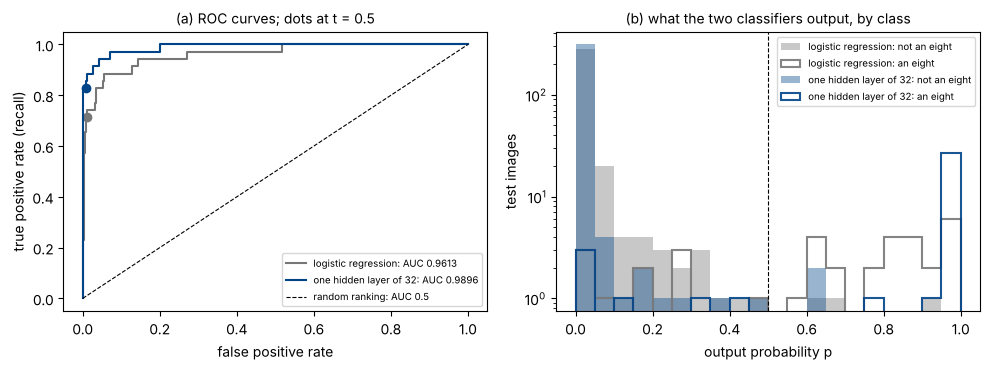

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for name, col in zip(models, (GREY, BLUE)):
    p = models[name]["p_test"]
    fpr, tpr, thr = roc_curve(y_test, p)
    auc_t, auc_r, auc_s = auc_trapezoid(fpr, tpr), roc_auc(y_test, p), skm.roc_auc_score(y_test, p)
    fpr_s, tpr_s, _ = skm.roc_curve(y_test, p, drop_intermediate=False)   # sklearn drops collinear points by default
    print(f"{name}: AUC trapezoid {auc_t:.5f}, ranks {auc_r:.5f}, sklearn {auc_s:.5f}; "
          f"ROC curve: {len(fpr)} points, identical to sklearn's: {np.allclose(fpr, fpr_s) and np.allclose(tpr, tpr_s)}")
    ax[0].plot(fpr, tpr, color=col, lw=1.5, label=f"{name}: AUC {auc_r:.4f}")
    k = np.searchsorted(-thr, -0.5)
    ax[0].plot(fpr[min(k, len(fpr) - 1)], tpr[min(k, len(tpr) - 1)], "o", color=col)
    bins = np.linspace(0, 1, 21)
    ax[1].hist(p[y_test == 0], bins=bins, color=col, alpha=0.4, label=f"{name}: not an eight")
    ax[1].hist(p[y_test == 1], bins=bins, color=col, alpha=0.9, histtype="step", lw=1.5, label=f"{name}: an eight")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="random ranking: AUC 0.5")
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate (recall)"); ax[0].legend(fontsize=7)
ax[0].set_title("(a) ROC curves; dots at t = 0.5", fontsize=10)
ax[1].axvline(0.5, color="k", ls="--", lw=0.8)
ax[1].set_yscale("log"); ax[1].set_xlabel("output probability p"); ax[1].set_ylabel("test images"); ax[1].legend(fontsize=7)
ax[1].set_title("(b) what the two classifiers output, by class", fontsize=10)
plt.tight_layout(); plt.show()

**Checkpoint.** The AUC of the network is close to one; the AUC of logistic
regression is clearly lower. What does an AUC of $0.99$ *mean*, in one
sentence about pairs of images? Why does the ROC curve not depend on the
threshold, and why would it not change if we doubled the number of eights in
the test set by copying them? The dots are the operating point at
$t=0.5$: moving the threshold slides the dot along the curve and changes the
confusion matrix — but not the curve and not the AUC. (Which threshold to
choose, and on which data, is next week's topic.)

### Step 5: the same with `scikit-learn` — the template for Project 2

Once your functions agree with the library, these are the calls to use in
the project: `y_test` the true labels, `p_test` the output probabilities of
your classifier, `y_pred = p_test > 0.5` the decisions. Nothing here needs
to know how the classifier was built.

[[323   2]
 [  6  29]]
accuracy 0.9778  precision 0.9355  recall 0.8286  F1 0.8788
              precision    recall  f1-score   support

not an eight       0.98      0.99      0.99       325
    an eight       0.94      0.83      0.88        35

    accuracy                           0.98       360
   macro avg       0.96      0.91      0.93       360
weighted avg       0.98      0.98      0.98       360

AUC 0.9896


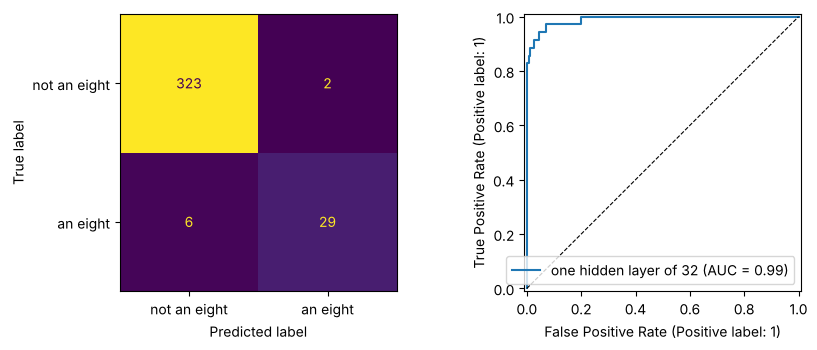

In [10]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

p_test = models["one hidden layer of 32"]["p_test"]   # replace by your classifier's output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)              # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["not an eight", "an eight"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["not an eight", "an eight"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="one hidden layer of 32")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

**Checkpoint.** `ConfusionMatrixDisplay` draws the matrix in `scikit-learn`'s
layout — true labels down the rows in the order 0, 1 — which is Eq. (5.67)
with both axes reversed. Say which cell is which before you paste the figure
into a report. For the $10\times10$ matrix of Project 2 the same two calls
work with the integer labels and `np.argmax` of the softmax output as
`y_pred`.

## Case 1: do you have the insight?

Discuss in your group, then in plenum.

1. **Accuracy.** Both classifiers scored above $0.95$ on "is it an eight?"
   while "never an eight" scores $0.90$. What fraction of the *remaining*
   error did each remove? Write the accuracy of each as
   $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$ and say which term
   carries it. Which single numbers survive the imbalance?
2. **The two errors.** Logistic regression and the network differ mostly in
   one of the four counts. Which one, what does it mean for an eight, and
   which measure is it that moves most between the two?
3. **The AUC.** State in one sentence, about pairs of images, what an AUC of
   $0.99$ means. Why does the ROC curve ignore the threshold and the class
   balance, and why does the precision–recall curve not?
4. **What a confusion matrix cannot say.** The AUC of logistic regression
   is $0.96$, not $0.5$ — most of the eights it misses at $t=0.5$ are still
   ranked above most non-eights. What does that tell you about the choice of
   threshold, and why is the matrix at $0.5$ nevertheless what Project 2
   asks for?

**What we hope you say.** (1) With $p_0$ the majority accuracy, the fraction
of error removed is $1-(1-\mathrm{acc})/(1-p_0)$; the accuracy is
$0.1\times\mathrm{recall}+0.9\times\mathrm{specificity}$, carried almost
entirely by the specificity, so a classifier that misses a quarter of the
eights still scores above $0.95$; balanced accuracy, $F_1$ and the MCC give
the majority rule $0.5$ or $0$ and do not reward it. (2) FN — the missed
eights; recall is the measure that moves. (3) Pick a random eight and a
random non-eight; with probability $0.99$ the eight gets the higher score.
The ROC curve is built from the ranking alone, and copying every eight
leaves every rate unchanged; precision has FP in its denominator, so the
fraction of positives enters it. (4) The threshold $0.5$ is a convention,
and a lower one would find more of the eights at the price of false alarms
— the operating point can be moved along the curve; choosing it, on
validation data and from the costs of the two errors, is next week. The
matrix at a stated threshold is what a user of the classifier experiences;
the AUC is what the model is capable of. A report gives both.

## Wrap-up, the exercises, and next week

**What you should own now.** A confusion matrix you can compute and read
without a library; accuracy, precision, recall and $F_1$ from their
definitions and from the table of Part A; the ROC curve and the AUC from a
sorted pass and from the rank formula, checked against `scikit-learn`; and
the `scikit-learn` calls for Project 2.

**Exercises week 43** (deadline **Friday October 23** at midnight): exercise
1 is exactly steps 3–5 as functions with a small test; exercise 2 is steps
1–4 on MNIST one-against-the-rest with your Project 2 classifiers; exercise
3 (optional) is the $10\times10$ matrix. One notebook per group in Canvas;
list your collaborators; finish the self-check table; declare your use of
LLMs.

**Next week (week 44).** Tuesday session and exercises: validation sets and
cross-validation for your Project 2 network — how to choose the
hyperparameters, and the threshold, without touching the test set. Monday:
Chapter 10 continued, equivariance and pooling.